# Solutions to notebook 13: When SymPy fails, and what to do about it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/13_when_sympy_fails.ipynb)

Worked solutions to the exercises at the end of [notebook 13](../notebooks/13_when_sympy_fails.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import quad

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

x = sp.symbols("x")          # no assumptions, as in the lesson

## Exercise 1

Explain why `sp.solve(x**2 - 2.0, x)` and `sp.solve(x**2 - 2, x)` print differently.

In [2]:
with_float = sp.solve(x**2 - 2.0, x)
with_integer = sp.solve(x**2 - 2, x)
with_float, with_integer

([-1.4142135623731, 1.4142135623731], [-√2, √2])

The only difference is `2.0` against `2`. Python hands SymPy a floating-point number in the
first case and an integer in the second. This is section 13.1: once a float is in an
expression, every result computed from it is a float too.

In [3]:
# the float roots are 15-digit approximations, the integer version gives exact square roots
assert all(isinstance(root, sp.Float) for root in with_float)
assert with_integer == [-sp.sqrt(2), sp.sqrt(2)]

# exact roots satisfy the equation exactly, the float root only to rounding error
assert with_integer[1] ** 2 - 2 == 0
print("float root squared, minus 2:", with_float[1] ** 2 - 2)
assert with_float[1] ** 2 - 2 != 0 and abs(with_float[1] ** 2 - 2) < 1e-14

# the two agree to the precision of a float, and nsimplify repairs the float input
assert abs(with_float[1] - with_integer[1].evalf()) < 1e-14
assert sp.solve(sp.nsimplify(x**2 - 2.0), x) == with_integer

float root squared, minus 2: 4.44089209850063e-16


**Answer.** `2.0` is a Python float, so SymPy treats the equation as approximate and returns
the approximate roots $\pm 1.41421356237310$. `2` is an exact integer, so the roots are the
exact numbers $\pm\sqrt2$. The float answer cannot be simplified further, cancelled against
another $\sqrt2$, or evaluated to more digits. Keep exact numbers in symbolic work and
convert to decimals at the end with `evalf`. If a float has already entered, `sp.nsimplify`
turns it back into an exact number.

## Exercise 2

`sp.simplify(sp.sqrt(x**2) - x)` is not zero. Find two different ways to make it zero.

In [4]:
expr = sp.sqrt(x**2) - x
sp.simplify(expr), expr.subs(x, -3), sp.refine(expr, sp.Q.real(x))

⎛        ____             ⎞
⎜       ╱  2              ⎟
⎝-x + ╲╱  x  , 6, -x + │x│⎠

SymPy is right not to simplify. For $x = -3$ the expression equals 6, and for any real $x$ it
is $|x| - x$. It is zero only when $x \ge 0$, and a symbol without assumptions could be
negative or complex (section 13.3). Both fixes consist of telling SymPy that $x$ is positive.

**Way 1.** Declare the assumption when the symbol is created.

In [5]:
x_positive = sp.symbols("x", positive=True)
way_1 = sp.sqrt(x_positive**2) - x_positive
way_1

0

**Way 2.** Keep the general symbol and supply the assumption for this one calculation with
`refine`.

In [6]:
way_2 = sp.refine(expr, sp.Q.positive(x))
way_2

0

In [7]:
# verify: the generic expression is not zero and has a counterexample, both fixes give zero,
# and the expression is zero at a positive number but not at a negative one
assert sp.simplify(expr) != 0 and expr.subs(x, -3) == 6
assert way_1 == 0 and way_2 == 0
assert expr.subs(x, 3) == 0

**Answer.** (1) Create the symbol with `positive=True` (or `nonnegative=True`), after which
$\sqrt{x^2}$ becomes $x$ automatically. (2) Use `sp.refine(expr, sp.Q.positive(x))`, which
applies the assumption to one expression without changing the symbol. A third option is
`sp.powdenest(expr, force=True)`, which assumes positivity without asking. Use it only when
you know the assumption holds.

In [8]:
assert sp.powdenest(expr, force=True) == 0

## Exercise 3

The integral $\int_0^1 x^x\,dx$ has no closed form. Evaluate it numerically in two ways and
compare with the series $\sum_{n=1}^{\infty} (-1)^{n+1} n^{-n}$. Hint: build the integral
with `sp.Integral(...)` before calling `.evalf()`; the object returned by `integrate` does
not evaluate here.

In [9]:
stuck = sp.integrate(x**x, (x, 0, 1))
stuck, isinstance(stuck, sp.Integral), type(stuck).__name__

(Integral(x**x, (x, 0, 1)), True, 'NonElementaryIntegral')

SymPy returns the integral unevaluated, as in section 13.5. The first numerical route taught
there is `.evalf()` on that object:

In [10]:
stuck.evalf()

1      
⌠      
⎮  x   
⎮ x  dx
⌡      
0      

With SymPy 1.14 this prints the integral again, not a number. The object that `integrate`
returned is a `NonElementaryIntegral`: SymPy has proved that no elementary antiderivative
exists, and marks the result with a special class that `evalf` does not evaluate in this
version. It is one more item for the list of symptoms in the lesson. The fix is to build the
plain unevaluated integral yourself with `sp.Integral`, which `evalf` does handle. The second
route is `scipy.integrate.quad` on a lambdified integrand.

In [11]:
value_sympy = sp.Integral(x**x, (x, 0, 1)).evalf(15)
value_scipy, error_estimate = quad(sp.lambdify(x, x**x, "numpy"), 0, 1)
assert isinstance(value_sympy, sp.Float)             # a number this time
value_sympy, value_scipy, error_estimate

(0.783430510712134, 0.7834305107121343, 3.351485755587191e-11)

The terms of the series shrink extremely fast (the tenth is $10^{-10}$), so a few terms are
enough. `Sum(...).evalf()` sums it to any number of digits.

In [12]:
n = sp.symbols("n", integer=True, positive=True)
series = sp.Sum((-1) ** (n + 1) * n ** (-n), (n, 1, sp.oo))
value_series = series.evalf(15)

for terms in (2, 4, 6, 8, 10):
    partial = sum(sp.Rational((-1) ** (j + 1), j**j) for j in range(1, terms + 1))
    print(f"{terms:2d} terms: {float(partial):.15f}")
print(f"  series: {value_series}")

 2 terms: 0.750000000000000
 4 terms: 0.783130787037037
 6 terms: 0.783429353566530
 8 terms: 0.783430508227564
10 terms: 0.783430510708738
  series: 0.783430510712134


In [13]:
# verify: the three values agree to 12 digits
assert abs(value_sympy - value_scipy) < 1e-12
assert abs(value_sympy - value_series) < 1e-12
assert abs(value_scipy - 0.783430510712134) < 1e-12

**Answer.** $\displaystyle\int_0^1 x^x\,dx = 0.783430510712\ldots$ by all three routes:
`sp.Integral(...).evalf()`, SciPy's `quad` and the series. They agree to better than $10^{-12}$, and ten terms of
the series already give 10 correct digits. The identity between the integral and the series is
known as the sophomore's dream.

## Exercise 4

The function $\dfrac{e^x - 1}{x}$ suffers from cancellation near zero. Show the problem with
`lambdify`, then fix it. (NumPy has `expm1` for exactly this purpose.)

The exact behaviour near zero comes from the limit and the series.

In [14]:
expr = (sp.exp(x) - 1) / x
sp.limit(expr, x, 0), sp.series(expr, x, 0, 4)

⎛            2    3        ⎞
⎜       x   x    x     ⎛ 4⎞⎟
⎜1, 1 + ─ + ── + ── + O⎝x ⎠⎟
⎝       2   6    24        ⎠

So for small $x$ the value must be $1 + x/2 + \dots$, slightly above 1. The naive `lambdify`
version does not deliver that:

In [15]:
naive = sp.lambdify(x, expr, "numpy")
exponents = [1, 5, 8, 12, 15, 16]
small = np.array([10.0 ** (-p) for p in exponents])

# reference values: exact rational input, evaluated with 30 digits
reference = np.array([float(expr.subs(x, sp.Rational(1, 10**p)).evalf(30)) for p in exponents])

for value, wrong, right in zip(small, naive(small), reference):
    print(f"x = {value:5.0e}    naive {wrong:.16f}    correct {right:.16f}")

x = 1e-01    naive 1.0517091807564771    correct 1.0517091807564762
x = 1e-05    naive 1.0000050000069649    correct 1.0000050000166667
x = 1e-08    naive 0.9999999939225290    correct 1.0000000050000000
x = 1e-12    naive 1.0000889005823410    correct 1.0000000000005000
x = 1e-15    naive 1.1102230246251565    correct 1.0000000000000004
x = 1e-16    naive 0.0000000000000000    correct 1.0000000000000000


At $x = 10^{-12}$ only four digits are right, at $10^{-15}$ the result is 11 % off, and at
$10^{-16}$ it is 0. In double precision $e^x$ is rounded to the nearest float near 1, which
keeps about 16 digits of $1 + x$. Subtracting 1 leaves only the few digits that belonged to
$x$.

**Fix.** SymPy has the function `expm1`, meaning $e^x - 1$ computed without the subtraction,
and `lambdify` translates it to `numpy.expm1`.

In [16]:
from sympy.codegen.cfunctions import expm1

stable_form = expm1(x) / x
assert sp.simplify(stable_form.rewrite(sp.exp) - expr) == 0        # the same function

stable = sp.lambdify(x, stable_form, "numpy")
for value, good, right in zip(small, stable(small), reference):
    print(f"x = {value:5.0e}    expm1 {good:.16f}    correct {right:.16f}")

x = 1e-01    expm1 1.0517091807564762    correct 1.0517091807564762
x = 1e-05    expm1 1.0000050000166667    correct 1.0000050000166667
x = 1e-08    expm1 1.0000000050000002    correct 1.0000000050000000
x = 1e-12    expm1 1.0000000000005000    correct 1.0000000000005000
x = 1e-15    expm1 1.0000000000000007    correct 1.0000000000000004
x = 1e-16    expm1 1.0000000000000000    correct 1.0000000000000000


In [17]:
# verify: the naive form really fails, the stable form matches the 30-digit reference
# and the series 1 + x/2 + x²/6
assert abs(naive(1e-12) - 1) > 1e-6 and naive(1e-16) == 0
assert np.allclose(stable(small), reference, rtol=1e-15, atol=0)
assert np.allclose(stable(small[1:]), 1 + small[1:] / 2 + small[1:] ** 2 / 6, rtol=1e-15, atol=0)

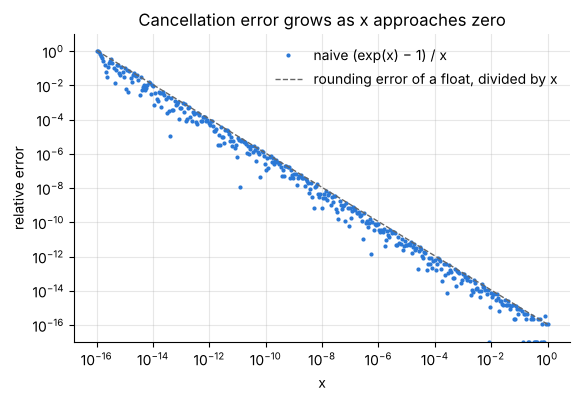

In [18]:
grid = np.logspace(-16, 0, 400)
relative_error = np.abs(naive(grid) / stable(grid) - 1)

fig, ax = plt.subplots()
ax.loglog(grid, np.maximum(relative_error, 1e-17), ".", ms=4, label="naive (exp(x) − 1) / x")
ax.loglog(grid, 1.1e-16 / grid, color="0.4", lw=1, ls="--", label="rounding error of a float, divided by x")
ax.set(xlabel="x", ylabel="relative error", ylim=(1e-17, 10),
       title="Cancellation error grows as x approaches zero")
ax.legend(frameon=False, loc="upper right");

**Answer.** The naive function loses about one digit for every factor of ten by which $x$
shrinks, and returns 0 instead of 1 at $x = 10^{-16}$. The relative error is roughly
$10^{-16}/x$. Writing the function as `expm1(x) / x` removes the subtraction, and the result
is then correct to full double precision for every $x$. Near zero the series
$1 + x/2 + x^2/6$ is an equally good fix.

## Exercise 5

Find the two positive roots of $\tan x = x$ below 10 (besides the obvious root $x = 0$).
Why does `nsolve` need care here, and how does bracketing help?

Start by trying `nsolve` from a range of guesses, as a student would.

In [19]:
f_tan = sp.tan(x) - x

for guess in (1.0, 3.0, 4.0, 4.5, 4.6, 5.0, 7.0, 7.7, 8.0):
    try:
        print(f"guess {guess}: {sp.nsolve(f_tan, x, guess)}")
    except ValueError:
        print(f"guess {guess}: nsolve failed")

guess 1.0: 0.000348227174421857
guess 3.0: 0.0000498014625195686
guess 4.0: -0.000510846762348789
guess 4.5: 4.49340945790906
guess 4.6: nsolve failed
guess 5.0: 0.000629717812823716
guess 7.0: nsolve failed
guess 7.7: 7.72525183693771
guess 8.0: nsolve failed


Only guesses very close to a root find it. Others fail, or land near zero from as far away as
5, with a poor value such as 0.0003 instead of 0. Following the third fix of section 13.6,
plot the two sides of the equation.

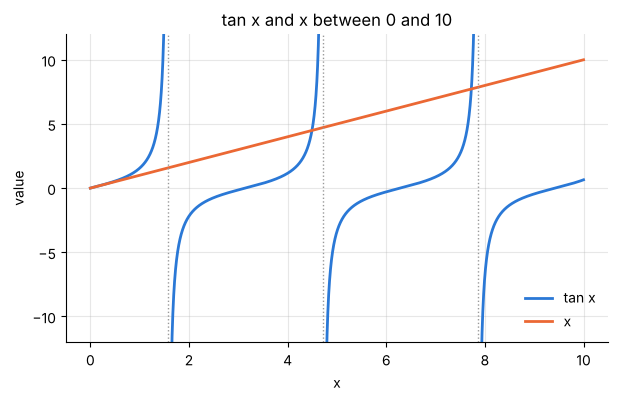

In [20]:
xs = np.linspace(0, 10, 4001)
tangent = np.tan(xs)
tangent[np.abs(tangent) > 14] = np.nan            # do not draw the jumps at the asymptotes

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, tangent, label="tan x")
ax.plot(xs, xs, label="x")
for pole in (0.5 * np.pi, 1.5 * np.pi, 2.5 * np.pi):
    ax.axvline(pole, color="0.6", lw=1, ls=":")
ax.set(xlabel="x", ylabel="value", ylim=(-12, 12), title="tan x and x between 0 and 10")
ax.legend(frameon=False, loc="lower right");

The dotted lines are the asymptotes of $\tan x$ at $\pi/2$, $3\pi/2$ and $5\pi/2$. Between two
asymptotes $\tan x - x$ rises steadily from $-\infty$ to $+\infty$ (its derivative is
$\tan^2 x \ge 0$), so each branch holds exactly one root. The first branch gives $x = 0$. On
the next two, the function is negative at $x = \pi$ and $x = 2\pi$ and positive just below the
asymptote, which gives a bracket for bisection. The fourth branch crosses the line near 10.9,
outside the interval.

In [21]:
brackets = [(k * np.pi, (k + 0.5) * np.pi - 1e-3) for k in (1, 2, 3)]
roots = [sp.nsolve(f_tan, x, bracket, solver="bisect") for bracket in brackets]
roots

[4.49340945790906, 7.72525183693771, 10.9041216594289]

A bracket must not contain an asymptote. The function also changes sign there, and bisection
would home in on the asymptote. `nsolve` notices that the function is not small at that point
and raises an error:

In [22]:
try:
    sp.nsolve(f_tan, x, (4.6, 5.0), solver="bisect")          # 3π/2 = 4.712 lies inside
except ValueError as err:
    print("ValueError:", str(err)[:42], "...")

ValueError: Could not find root within given tolerance ...


**Verify** by substitution, and with a second formulation. Multiplying the equation by
$\cos x$ gives $\sin x - x\cos x = 0$, which has the same roots and no asymptotes (the first
fix of section 13.6: reformulate). `nsolve` then converges from rough guesses, and a scan for
sign changes confirms how many roots there are.

In [23]:
smooth = sp.sin(x) - x * sp.cos(x)

for root, guess in zip(roots, (4, 8, 11)):
    assert abs(sp.tan(root) - root) < 1e-10                    # substitution back
    assert abs(sp.nsolve(smooth, x, guess) - root) < 1e-10     # second method

# tabulated values of the first two positive roots
assert abs(roots[0] - 4.493409457909) < 1e-10 and abs(roots[1] - 7.725251836937) < 1e-10
assert roots[2] > 10                                           # the next root is outside the interval

# exactly two sign changes of the smooth form for 0 < x <= 10
scan = sp.lambdify(x, smooth, "numpy")(np.linspace(0.5, 10, 2000))
assert np.count_nonzero(np.sign(scan[:-1]) != np.sign(scan[1:])) == 2

# and x = 0 is a root by inspection
assert f_tan.subs(x, 0) == 0

**Answer.** The roots between 0 and 10 are

$$x = 0, \qquad x = 4.493409, \qquad x = 7.725252 .$$

The next one is 10.904. `nsolve` needs care for three reasons. The function $\tan x - x$ jumps
from $+\infty$ to $-\infty$ at every asymptote, and each root sits just below one, where the
curve is very steep, so Newton's iteration started a short distance away is thrown onto another
branch. A sign change does not guarantee a root, because the function also changes sign at the
asymptotes. And $x = 0$ is a triple root ($\tan x - x \approx x^3/3$), near which the iteration
converges slowly and stops early. Bracketing helps because bisection cannot leave its interval:
choose an interval that lies on one branch and has a sign change, such as
$(k\pi,\ (k + \tfrac12)\pi - 0.001)$, and it must converge to the single root on that branch.